# Travail 1 — RNN, LSTM, Transformer, GPT et BERT

Ce notebook réalise les six tâches demandées :

1. Générer une série temporelle `y = sin(x)`.
2. Entraîner et tester un RNN pour prédire la valeur suivante à partir de 10 valeurs.
3. Entraîner et tester un LSTM sur la même tâche.
4. Entraîner et tester un Transformer sur la même tâche.
5. Utiliser un modèle de type GPT pour générer la suite d'un texte.
6. Utiliser un modèle de type BERT pour prédire un mot masqué.

Les trois modèles de prévision utilisent exactement les mêmes données d'entraînement et de test.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from copy import deepcopy

torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)

Device : cpu


## 1. Générer la série temporelle et créer les séquences

Chaque exemple contient 10 valeurs consécutives et la cible est la valeur située immédiatement après.

Exemple : `[y0, ..., y9]` doit prédire `y10`.

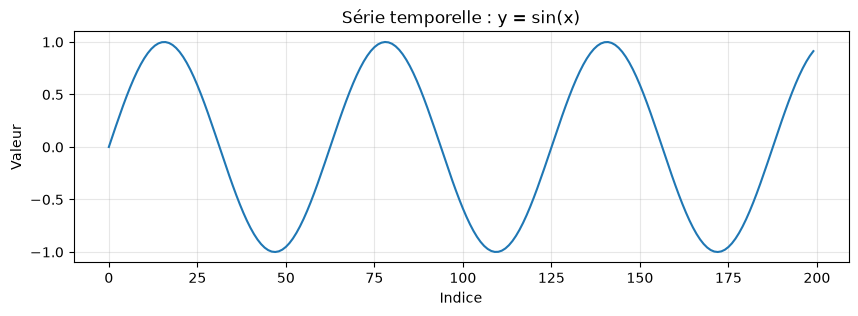

X_train : (150, 10, 1) | y_train : (150, 1)
X_test  : (40, 10, 1) | y_test  : (40, 1)


In [2]:
serie = torch.sin(torch.linspace(0, 20, 200))
longueur_sequence = 10
X = torch.stack([
    serie[i:i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])
y = torch.stack([
    serie[i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])

# Une seule variable observée à chaque instant.
X = X.unsqueeze(-1)
y = y.unsqueeze(-1)
X_train, y_train = X[:150], y[:150]
X_test, y_test = X[150:], y[150:]

plt.figure(figsize=(10, 3))
plt.plot(serie.numpy())
plt.title("Série temporelle : y = sin(x)")
plt.xlabel("Indice")
plt.ylabel("Valeur")
plt.grid(alpha=0.3)
plt.show()

print("X_train :", tuple(X_train.shape), "| y_train :", tuple(y_train.shape))
print("X_test  :", tuple(X_test.shape), "| y_test  :", tuple(y_test.shape))

## 2. Modèle RNN

Le RNN lit les 10 valeurs l'une après l'autre. Son dernier état caché résume la séquence, puis une couche linéaire produit une seule prédiction.

In [3]:
class ModeleRNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.rnn = nn.RNN(input_size=1, hidden_size=16, batch_first=True)
        self.sortie = nn.Linear(16, 1)

    def forward(self, x):
        etats, _ = self.rnn(x)
        return self.sortie(etats[:, -1, :])


class ModeleLSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=16, batch_first=True)
        self.sortie = nn.Linear(16, 1)

    def forward(self, x):
        etats, _ = self.lstm(x)
        return self.sortie(etats[:, -1, :])


class ModeleTransformer(nn.Module):
    def __init__(self, longueur_max=10):
        super().__init__()
        dimension = 16
        self.projection = nn.Linear(1, dimension)
        self.positions = nn.Embedding(longueur_max, dimension)
        couche = nn.TransformerEncoderLayer(
            d_model=dimension,
            nhead=2,
            dim_feedforward=32,
            dropout=0.0,
            batch_first=True,
        )
        self.encodeur = nn.TransformerEncoder(couche, num_layers=1)
        self.sortie = nn.Linear(dimension, 1)

    def forward(self, x):
        positions = torch.arange(x.shape[1], device=x.device)
        z = self.projection(x) + self.positions(positions)[None, :, :]
        z = self.encodeur(z)
        return self.sortie(z[:, -1, :])


print("Les trois modèles sont définis.")

Les trois modèles sont définis.


## 3. Entraîner et tester les trois modèles

La perte utilisée est l'erreur quadratique moyenne (`MSELoss`). Après chaque entraînement, on calcule la MSE sur le test puis on trace les valeurs réelles et prédites.

In [4]:
def entrainer(modele, epochs=300, taux_apprentissage=0.01):
    modele = modele.to(device)
    critere = nn.MSELoss()
    optimiseur = torch.optim.Adam(modele.parameters(), lr=taux_apprentissage)
    historique = []
    entrees = X_train.to(device)
    cibles = y_train.to(device)

    for epoch in range(epochs):
        modele.train()
        predictions = modele(entrees)
        perte = critere(predictions, cibles)
        optimiseur.zero_grad()
        perte.backward()
        optimiseur.step()
        historique.append(perte.item())
    return modele, historique


def tester(modele):
    modele.eval()
    with torch.no_grad():
        predictions = modele(X_test.to(device)).cpu()
        perte = nn.functional.mse_loss(predictions, y_test)
    return predictions, perte.item()


modeles = {}
historiques = {}
for nom, constructeur in [
    ("RNN", ModeleRNN),
    ("LSTM", ModeleLSTM),
    ("Transformer", ModeleTransformer),
]:
    modeles[nom], historiques[nom] = entrainer(constructeur())
    predictions, perte_test = tester(modeles[nom])
    modeles[nom].predictions_test = predictions
    print(f"{nom:11s} | MSE test : {perte_test:.6f}")

RNN         | MSE test : 0.000028
LSTM        | MSE test : 0.000010
Transformer | MSE test : 0.000053


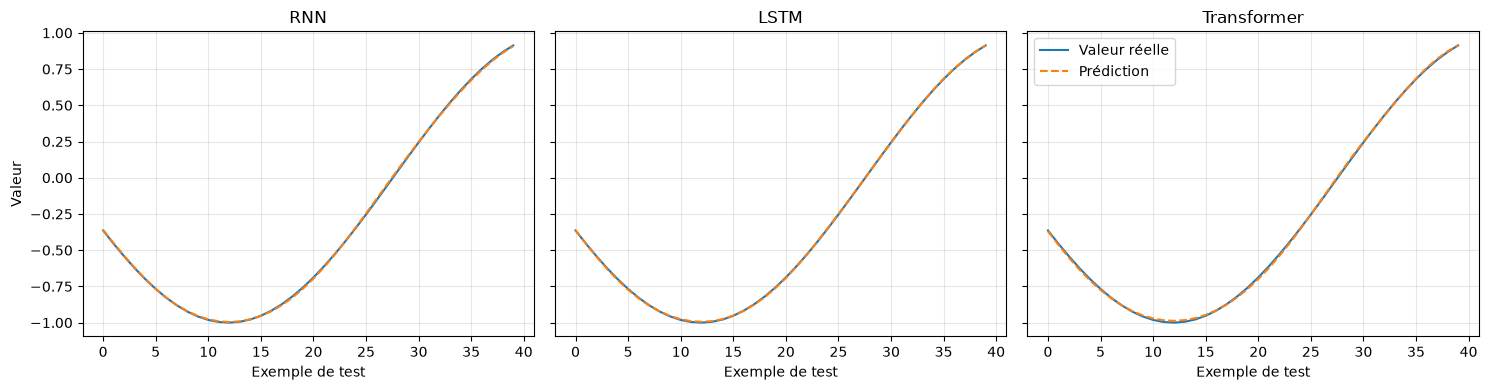

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for axe, (nom, modele) in zip(axes, modeles.items()):
    axe.plot(y_test.squeeze().numpy(), label="Valeur réelle")
    axe.plot(modele.predictions_test.squeeze().numpy(), "--", label="Prédiction")
    axe.set_title(nom)
    axe.set_xlabel("Exemple de test")
    axe.grid(alpha=0.3)
axes[0].set_ylabel("Valeur")
axes[-1].legend()
plt.tight_layout()
plt.show()

### Comparaison et interprétation

Les trois modèles apprennent la dynamique locale de la sinusoïde. Le RNN possède une mémoire récurrente simple, le LSTM ajoute des portes pour mieux contrôler cette mémoire, et le Transformer compare directement les positions grâce à l'attention. Les résultats peuvent varier légèrement selon l'initialisation.

## 4. Exemple GPT : prédire la suite d'un texte

GPT est un Transformer de type décodeur. Il prédit le prochain token uniquement à partir du contexte précédent. Le premier lancement télécharge le modèle et son tokenizer.

In [6]:
from transformers import AutoTokenizer, AutoModelForCausalLM

nom_modele_gpt = "gpt2"
tokenizer_gpt = AutoTokenizer.from_pretrained(nom_modele_gpt)
modele_gpt = AutoModelForCausalLM.from_pretrained(nom_modele_gpt)
tokenizer_gpt.pad_token = tokenizer_gpt.eos_token
modele_gpt.config.pad_token_id = tokenizer_gpt.pad_token_id
modele_gpt.eval()

amorce = "Artificial intelligence can help people"
entrees = tokenizer_gpt(amorce, return_tensors="pt")
with torch.no_grad():
    sortie = modele_gpt.generate(
        **entrees,
        max_new_tokens=50,
        do_sample=True,
        temperature=0.8,
        top_p=0.9,
        pad_token_id=tokenizer_gpt.pad_token_id,
    )
texte_genere = tokenizer_gpt.decode(sortie[0], skip_special_tokens=True)
print(texte_genere)

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

c:\Users\Lenovo\Downloads\Architecture-Transformer\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Lenovo\.cache\huggingface\hub\models--gpt2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

... (2 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Artificial intelligence can help people find solutions to a myriad of problems. It could be an option for the public at large.

In the meantime, the question is whether the AI will be able to provide us with a new way of interacting with the world.


`temperature < 1` rend la génération plus prévisible. Une température supérieure à 1 augmente la diversité, mais peut diminuer la cohérence. `top_p` limite le tirage aux tokens les plus probables.

## 5. Exemple BERT : prédire un mot masqué

BERT est un Transformer bidirectionnel. Il peut utiliser le contexte situé avant et après `[MASK]`, contrairement à GPT qui prédit la suite de gauche à droite.

In [7]:
from transformers import AutoTokenizer, AutoModelForMaskedLM

nom_modele_bert = "bert-base-multilingual-cased"
tokenizer_bert = AutoTokenizer.from_pretrained(nom_modele_bert)
modele_bert = AutoModelForMaskedLM.from_pretrained(nom_modele_bert)
modele_bert.eval()

texte_masque = f"Rabat est la {tokenizer_bert.mask_token} du Maroc."
entrees = tokenizer_bert(texte_masque, return_tensors="pt")
position_masque = (
    entrees["input_ids"][0] == tokenizer_bert.mask_token_id
).nonzero(as_tuple=True)[0].item()

with torch.no_grad():
    logits = modele_bert(**entrees).logits[0, position_masque]
probabilites = torch.softmax(logits, dim=-1)
top_probabilites, top_indices = torch.topk(probabilites, k=5)

print("Phrase :", texte_masque)
for probabilite, indice in zip(top_probabilites, top_indices):
    mot = tokenizer_bert.decode([indice.item()]).strip()
    print(f"{probabilite.item():.2%} | {texte_masque.replace(tokenizer_bert.mask_token, mot)}")

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

c:\Users\Lenovo\Downloads\Architecture-Transformer\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Lenovo\.cache\huggingface\hub\models--bert-base-multilingual-cased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] BertForMaskedLM LOAD REPORT from: bert-base-multilingual-cased
Key                         | Status     |  | 
----------------------------+------------+--+-
bert.pooler.dense.bias      | UNEXPECTED |  | 
bert.pooler.dense.weight    | UNEXPECTED |  | 
cls.seq_relationship.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Phrase : Rabat est la [MASK] du Maroc.
86.06% | Rabat est la capitale du Maroc.
5.19% | Rabat est la ville du Maroc.
5.03% | Rabat est la préfecture du Maroc.
0.85% | Rabat est la Rabat du Maroc.
0.58% | Rabat est la capital du Maroc.


## Conclusion

- Le RNN, le LSTM et le Transformer prédisent la prochaine valeur de la sinusoïde.
- GPT prédit le prochain token et génère progressivement une continuation.
- BERT utilise les deux côtés du contexte pour reconstruire un token masqué.

Les modèles GPT et BERT utilisés ici sont préentraînés. Leur chargement nécessite Internet au premier lancement.